In [2]:
#| include: false
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from scipy.constants import Boltzmann as k_B
from scipy.constants import elementary_charge as e
from scipy.constants import epsilon_0

plt.rcParams.update(
    {
        "font.size": 14,
        "axes.labelsize": 15,
        "axes.titlesize": 17,
        "legend.fontsize": 11,
        "lines.linewidth": 2.5,
    }
)


def bjerrum_length(T, eps_r):
    """Bjerrum length in Å."""
    return e**2 / (4 * np.pi * epsilon_0 * eps_r * k_B * T) * 1e10


D3_URL = "https://cdn.jsdelivr.net/npm/d3@7.9.0/dist/d3.min.js"


def explorable(name):
    """Interactive D3 diagram from explorables/<name>.js; runs in JupyterLab and Quarto."""
    body = (Path("explorables") / f"{name}.js").read_text()
    uid = f"explorable-{uuid4().hex[:8]}"
    # d3's UMD build registers with require.js if present; hide it so d3 lands on window.
    loader = f"""
(function () {{
  var el = document.getElementById("{uid}");
  function run(d3) {{
{body}
  }}
  if (window.d3) return run(window.d3);
  var amd = window.define;
  window.define = undefined;
  var s = document.createElement("script");
  s.src = "{D3_URL}";
  s.onload = function () {{ window.define = amd; run(window.d3); }};
  document.head.appendChild(s);
}})();"""
    return HTML(f'<div id="{uid}"></div><script>{loader}</script>')

## 1. Question: why do neutral molecules stick together?

Normal boiling points of small molecules:

| | Ne | CH$_4$ | NH$_3$ | H$_2$O | Ar | HCl | HI |
|---|---|---|---|---|---|---|---|
| $M$ (g/mol) | 20 | 16 | 17 | 18 | 40 | 36 | 128 |
| $T_b$ (°C) | −246 | −162 | −33 | 100 | −186 | −85 | −35 |

None of them carries a net charge, so Coulomb's law between ions (day 2) gives nothing.

**Question:** What attracts them? Why is water so different from methane, and HI from HCl? Keep your answers; we return to them at the end.

## 2. What gives a molecule a dipole?

Day 2: $\boldsymbol\mu = \sum_i q_i\mathbf r_i$, unit debye, $1\ e\cdot$Å $= 4.80$ D.

Bond dipoles add as vectors, so **symmetry** can cancel them:

| | CO$_2$ | CH$_4$ | CCl$_4$ | C$_6$H$_6$ | CHCl$_3$ | NH$_3$ | H$_2$O |
|---|---|---|---|---|---|---|---|
| $\mu$ (D) | 0 | 0 | 0 | 0 | 1.01 | 1.47 | 1.85 |

Source: Dill Table 24.1.

Proteins carry ionizable side chains (Asp, Glu, Lys, Arg, His, termini). How they are spread over the surface sets both the net charge $Q$ and the dipole moment $\mu$, often hundreds of debye.

**Question:** CO$_2$ has two polar C=O bonds but no dipole. Why? And why does water have one?

## 3. Multipole expansion

A charge $q_1$ at distance $R$ from a group of charges $q_i$ at $\mathbf r_i$ (with $r_i \ll R$). Expanding $1/|\mathbf R - \mathbf r_i|$ in powers of $r_i/R$:

$$u = \frac{q_1}{4\pi\epsilon_0\epsilon_r}\left[\frac{\sum_i q_i}{R} + \frac{\mu\cos\theta}{R^2} + \frac{(\text{quadrupole})}{R^3} + \cdots\right]$$

- **monopole** (net charge), **dipole**, **quadrupole**, …: the first non-zero term dominates far away
- each order decays one power of $R$ faster
- for fixed orientations: ion–ion $R^{-1}$, ion–dipole $R^{-2}$, dipole–dipole $R^{-3}$

Derivation with SymPy: [multipole notebook](https://github.com/luchem/notebooks/blob/main/physical/multipole_expansion.ipynb) ([Colab](https://colab.research.google.com/github/luchem/notebooks/blob/main/physical/multipole_expansion.ipynb)).

## When is the dipole term enough? {.nostretch}

Interaction energy of an ion on the axis of a $\pm q$ pair (separation $d$), facing its negative end. The energy is attractive, so $|u|$ is plotted.

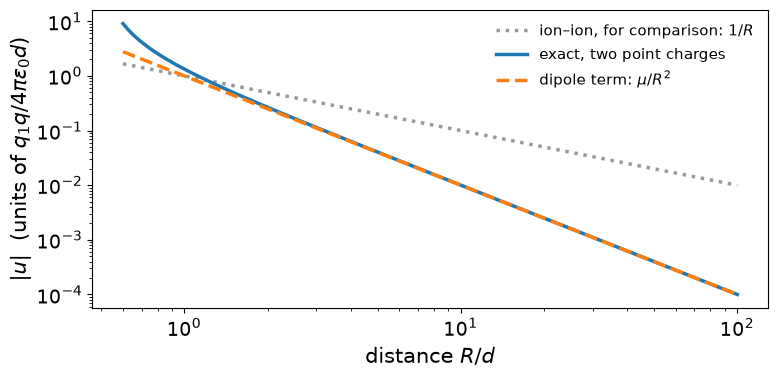

In [3]:
# Ion on the axis of a ±q pair with separation d, negative end nearest the ion.
R = np.logspace(np.log10(0.6), 2, 300)  # R/d
exact = 1 / (R + 0.5) - 1 / (R - 0.5)  # u in units of q1 q / (4πε0 d)
dipole = -1 / R**2

fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(R, 1 / R, color="0.6", ls=":", label="ion–ion, for comparison: $1/R$")
ax.loglog(R, -exact, label="exact, two point charges")
ax.loglog(R, -dipole, ls="--", label=r"dipole term: $\mu/R^2$")
ax.set_xlabel("distance $R/d$")
ax.set_ylabel(r"$|u|$  (units of $q_1q/4\pi\epsilon_0 d$)")
ax.legend(frameon=False)
plt.tight_layout()

Beyond a few $d$, the point dipole is accurate. Close to the molecule, higher multipoles matter.

## 4. Two dipoles with fixed orientations {.nostretch}

$$\frac{u}{k_BT} = \frac{\ell_B\,\mu_1\mu_2}{r^3}\left(\cos\theta_{12} - 3\cos\theta_1\cos\theta_2\right)$$

is the interaction energy; $\mu$ in $e\cdot$Å, $\theta_1, \theta_2$ to the centre line, $\theta_{12}$ between dipoles.

In [4]:
explorable("dipole_pair")

**Question** (Dill 24.4): Which side-by-side pair has the lower energy, parallel or antiparallel? By what factor does $u$ change if you double $r$?

## 5. Counting orientations {.nostretch}

In [5]:
explorable("angle_scan")

Each dot is a state, a direction of the dipole $\boldsymbol{\mu}$; turning about the axis changes nothing, so most states lie near 90°. Anti-aligned states (blue) weigh little but still count: **orientational entropy**. **Question:** What happens to the blue share as $T$ rises?

## Orientational averaging: the math

Ion and dipole at fixed distance $r$: $u(\theta) = -u_0\cos\theta$ with $u_0/k_BT = x = \ell_B z\mu/r^2$.

- all angles equally likely: $\langle\cos\theta\rangle = 0$, the interaction averages to **zero**
- Boltzmann weighting favours the low-energy angles, so the average is **attractive**

$$\langle u\rangle = \frac{\int u\,e^{-u/k_BT}\,d\Omega}{\int e^{-u/k_BT}\,d\Omega}\approx -\frac{u_0^2}{3k_BT}
\qquad
w = -k_BT\ln\left\langle e^{-u/k_BT}\right\rangle_{\!\text{free}} = -k_BT\ln\frac{\sinh x}{x}\approx -\frac{u_0^2}{6k_BT}$$

- the approximations hold for $x \ll 1$: expand $e^{-u/k_BT}$ to second order (Dill Eqs. 24.5–24.7)
- $w$ is a **free energy** (potential of mean force); $\langle u\rangle = 2w$ at high $T$
- both depend on temperature, even with $\epsilon_r$ fixed

## Alignment against thermal motion {.nostretch}

In [6]:
explorable("orientation")

**Question:** What does raising $T$ do to $x$, to the alignment, and to $w$?

## 6. Interactions with rotating dipoles

Free energies $w$ in units of $k_BT$, with $\mu$ in $e\cdot$Å and $\ell_B = e^2/4\pi\epsilon_0\epsilon_rk_BT$:

| Interaction | Fixed orientation | Freely rotating, $w/k_BT$ |
|---|---|---|
| ion–ion | $\ell_B z_1z_2/r$ | $\ell_B z_1z_2/r$ |
| ion–dipole | $\propto r^{-2}$ | $-(\ell_B z\mu)^2/6r^4$ |
| dipole–dipole (Keesom) | $\propto r^{-3}$ | $-(\ell_B\mu_1\mu_2)^2/3r^6$ |

- tumbling shortens the range: $r^{-2}\to r^{-4}$ and $r^{-3}\to r^{-6}$
- Dill Eqs. 24.7 and 24.8 give the average energy $\langle u\rangle = 2w$

Example (Dill 24.1): two ethanol molecules ($\mu = 1.69$ D) 10 Å apart in the gas phase at 300 K: $\langle u\rangle = -8.3$ J/mol, far below $RT = 2.5$ kJ/mol. At 5 Å it is $2^6 = 64$ times stronger.

## 7. Polarizability: induced dipoles

An electric field pulls the electron cloud one way and the nuclei the other:

$$\boldsymbol\mu_{\rm ind} = \alpha\mathbf E, \qquad \alpha' = \frac{\alpha}{4\pi\epsilon_0}\ \text{(polarizability volume, Å}^3)$$

- $\alpha'$ is close to the molecular volume: He 0.20, Ar 1.66, CH$_4$ 2.60, CCl$_4$ 10.5 Å$^3$
- large, diffuse electron clouds are easy to deform
- energy of the induced dipole: $u = -\tfrac12\alpha E^2$; the $\tfrac12$ is the work spent polarizing the molecule

Ion–induced dipole, and permanent dipole–induced dipole (**Debye**):

$$\frac{u}{k_BT} = -\frac{\ell_B z^2\alpha'}{2r^4}, \qquad
\frac{w_{\rm Debye}}{k_BT} = -\frac{\ell_B\left(\mu_1^2\alpha_2' + \mu_2^2\alpha_1'\right)}{r^6}$$

## Polarizing a peptide group {.nostretch}

In [7]:
explorable("polarization")

Each atom responds only to the source's field; in reality the induced dipoles also polarize each other. **Question:** Why does the energy stay negative when you flip the sign of the ion? Why is HI more polarizable than HCl?

## 8. Dispersion (London) forces

Even an argon atom has a fluctuating dipole: at any instant the electrons are not centred on the nucleus.

- the instantaneous dipole polarizes a neighbour, and the two fluctuations become correlated
- always attractive, present between **all** molecules
- quantum mechanical in origin; London (1930)

For two identical molecules with ionization energy $I$:

$$u_{\rm London} \approx -\frac{3}{4}\frac{I\,\alpha'^2}{r^6}$$

**Question:** Why does argon condense at all? Why does $T_b$ rise from Ne to Ar, and from HCl to HI?

## van der Waals forces {.nostretch}

Keesom + Debye + London, all $w = -C/r^6$. Coefficients from $\mu$, $\alpha'$ (Dill Table 24.1) and $I$, at 300 K:

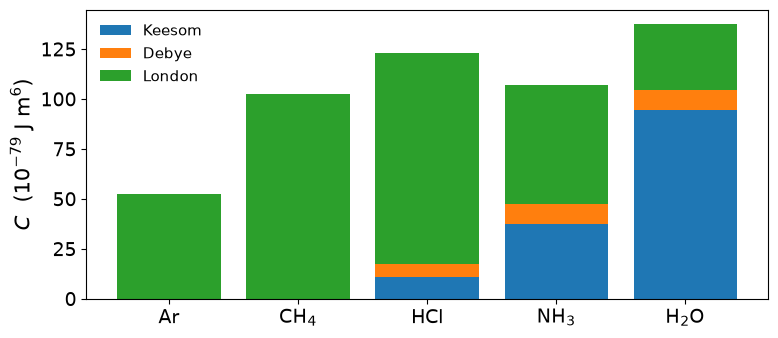

In [8]:
# C in w = -C/r^6, in units of 1e-79 J m^6; same molecule pairs.
lB = bjerrum_length(300, 1)
kT = k_B * 300
to_C = kT * 1e-60 / 1e-79  # kT·Å^6 -> 1e-79 J m^6
mol = {  # mu (D), alpha' (Å^3), ionization energy (eV)
    "Ar": (0, 1.66, 15.76),
    "CH$_4$": (0, 2.60, 12.61),
    "HCl": (1.08, 2.63, 12.74),
    "NH$_3$": (1.47, 2.22, 10.07),
    "H$_2$O": (1.85, 1.48, 12.62),
}
terms = {"Keesom": [], "Debye": [], "London": []}
for mu, a, I in mol.values():
    mu /= 4.803  # e·Å
    terms["Keesom"].append((lB * mu**2) ** 2 / 3 * to_C)
    terms["Debye"].append(2 * lB * mu**2 * a * to_C)
    terms["London"].append(0.75 * I * e / kT * a**2 * to_C)

fig, ax = plt.subplots(figsize=(8, 3.6))
bottom = np.zeros(len(mol))
for name, c in terms.items():
    ax.bar(list(mol), c, bottom=bottom, label=name)
    bottom += c
ax.set_ylabel(r"$C$  ($10^{-79}$ J m$^6$)")
ax.legend(frameon=False)
plt.tight_layout()

Dispersion dominates for all but the most polar molecules. This $r^{-6}$ attraction is the attractive term of the Lennard–Jones potential (day 1).

## Back to the question

- Ne, Ar, CH$_4$: dispersion only; it grows with $\alpha'$, so with the size of the electron cloud
- HCl → HI: the dipole falls, but $\alpha'$ rises, and dispersion wins
- H$_2$O: small $\alpha'$, yet $T_b = 100$ °C. Keesom is large, and **hydrogen bonds** add more. These are directional and short-ranged, beyond what a point dipole describes (Dill p. 478)

**Question:** Two proteins in water, one charged, one with a large dipole. Which of today's terms act between them, and what else could?

## Summary

- multipole expansion: monopole, dipole, quadrupole, …; ranges $r^{-1}$, $r^{-2}$, $r^{-3}$ for fixed orientations
- rotation averages $u$ to zero, but Boltzmann weighting leaves an attraction: $r^{-4}$ (ion–dipole), $r^{-6}$ (Keesom)
- the averaged interaction is a temperature-dependent free energy, $w = \langle u\rangle/2$
- polarizability $\alpha'$ ≈ molecular volume; induced dipoles attract ions and dipoles (Debye)
- dispersion acts between all molecules, scales as $\alpha'^2$ and usually dominates
- van der Waals = Keesom + Debye + London, all $r^{-6}$: the attraction in the Lennard–Jones potential

**Now:** problems 1–3 and Dill 24.4.
**Next time:** …